<a href="https://colab.research.google.com/github/Nasim-Amani/ramp-aware-solar/blob/main/E2_Lambda_Sweep.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# E2: weight λ of the ramp term (univariate LSTM)

## Why this experiment
In E1, the ramp-aware loss with **λ = 1** made the LSTM catch about 35 times more ramps than plain MSE (λ = 0), but it also cost accuracy: on the broken-cloud day the MSE model was about 4 % better than persistence in RMSE, the ramp-aware model only about equal. λ = 1 was not tuned, so it may be too strong.

**Question:** how do accuracy and ramp detection change as λ increases, and is there a λ that keeps most of the accuracy of plain MSE while still catching a good share of the ramps?

## Setup
Everything is the same as in E1: univariate input (the last 10 min of 10-s irradiance), output 10–60 s ahead, the **value** target (chosen in E1), the same split, threshold and evaluation. Only λ changes:

| λ | Seeds | Note |
|---|---|---|
| 0 (plain MSE) | 0, 1, 2 | from E1 |
| 0.1 | 0 | new |
| 0.3 | 0 | new |
| 1 | 0, 1, 2 | from E1 |
| 3 | 0 | new |

The new λ values are trained with one seed. The 3 seeds of λ = 0 and λ = 1 show how much results vary by chance (in E1: about ± 44 ramps caught and ± 2–3 W/m² in cloudy-day RMSE); a difference between two λ values counts only if it is clearly larger than this. The chosen λ is then confirmed with two more seeds (section 9).

**Forecasts from E1 are reused:** if the E1 forecast files (`pred_level_lam0.0_seed*.npy`, `pred_level_lam1.0_seed*.npy`) are in the Colab session, these runs are not trained again. Otherwise they are trained here.

## 1. Settings

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

STEP_S   = 10                          # resolution: 10-s averages
LOOKBACK = 60                          # input:  the last 60 steps (10 min)
HORIZON  = 6                           # output: the next 6 steps (10, 20, ..., 60 s)
LEADS    = STEP_S * np.arange(1, HORIZON + 1)

HP = {"units": 64, "learning_rate": 1e-3, "batch_size": 128,
      "max_epochs": 100, "patience": 10}   # same as E1

TARGET  = "level"                      # value target (chosen in E1)
INPUTS  = ["G"]                        # univariate
LAMBDAS = [0.0, 0.1, 0.3, 1.0, 3.0]    # weights of the ramp term

# Runs: (λ, seed). λ = 0 and λ = 1 with 3 seeds (from E1), the new λ values with seed 0
RUNS = [(lam, s) for lam in [0.0, 1.0] for s in [0, 1, 2]] + [(lam, 0) for lam in [0.1, 0.3, 3.0]]

RESULTS_FILE = "E2_results.csv"        # one row per newly trained run (log)

## 2. Data
1-s irradiance (`Solar_Rad_clean`), daylight records of the 11 complete days, averaged to 10 s (the model resolution chosen in the data exploration). Only irradiance is used as input in E1.

In [ ]:
df = pd.read_csv("solar_data_final_columns.csv", index_col="DateTime", parse_dates=["DateTime"])

data = (df.loc[df["full_day"] & df["daylight"], ["Solar_Rad_clean"]]
          .rename(columns={"Solar_Rad_clean": "G"})        # G = irradiance (W/m²)
          .resample(f"{STEP_S}s").mean()
          .dropna())     # removes only the night steps (checked: no NaN and no gaps inside daylight)

print(f"10-s daylight steps: {len(data):,}")

10-s daylight steps: 46,794


## 3. Split and day types
- **Split by whole days, in time order:** train 16–23 Feb, validation 24 Feb, test 25 Feb (broken clouds) and 26 Feb (clear).
- **Day types** come from the Variability Index in the data exploration notebook.

In [ ]:
days = sorted(set(data.index.date))
TRAIN_DAYS, VAL_DAYS, TEST_DAYS = days[:8], days[8:9], days[9:]

# Day types from the Variability Index (data exploration notebook)
DAY_TYPE = {pd.Timestamp(d).date(): typ for d, typ in {
    "2013-02-16": "clear",         "2013-02-17": "few clouds",    "2013-02-18": "broken clouds",
    "2013-02-19": "clear",         "2013-02-20": "broken clouds", "2013-02-21": "clear",
    "2013-02-22": "clear",         "2013-02-23": "few clouds",    "2013-02-24": "broken clouds",
    "2013-02-25": "broken clouds", "2013-02-26": "clear"}.items()}

for name, dl in [("train", TRAIN_DAYS), ("validation", VAL_DAYS), ("test", TEST_DAYS)]:
    print(f"{name:11s}", ", ".join(f"{d:%d %b} ({DAY_TYPE[d]})" for d in dl))

train       16 Feb (clear), 17 Feb (few clouds), 18 Feb (broken clouds), 19 Feb (clear), 20 Feb (broken clouds), 21 Feb (clear), 22 Feb (clear), 23 Feb (few clouds)
validation  24 Feb (broken clouds)
test        25 Feb (broken clouds), 26 Feb (clear)


## 4. Ramp threshold

**Goal:** decide how large a 10-s change must be to count as a ramp, based on the data.

1. **10-s changes.** For each day, we subtract each 10-s value from the next one, e.g. 790 → 650 W/m² gives a change of −140 W/m². Changes are only computed between values that are exactly 10 s apart.
2. **Which days.** We use only the broken-cloud **training** days (18 and 20 Feb): clear days have almost only tiny changes, and the test days must not influence a threshold that is later used to score the models. Drops and rises are treated the same, so we use the size of each change (−140 and +140 both count as 140).
3. **Threshold.** A ramp is a change among the largest 5 % of these changes, i.e. larger than their 95th percentile. Rounded to 10 W/m², this gives **80 W/m² per 10 s**.

All ramp results use this threshold. As a sensitivity check, we also report results at 60 W/m².

In [ ]:
def changes_of_day(day):
    # 10-s changes of irradiance within one day, only between real neighbouring steps
    g = data.loc[data.index.date == day, "G"]
    ok = g.index.to_series().diff() == pd.Timedelta(seconds=STEP_S)
    return g.diff()[ok]

broken_train = [d for d in TRAIN_DAYS if DAY_TYPE[d] == "broken clouds"]
train_changes = pd.concat([changes_of_day(d) for d in broken_train]).abs()

THRESHOLD       = int(round(np.percentile(train_changes, 95), -1))   # main threshold (W/m² per 10 s)
THRESHOLD_CHECK = 60                                                  # sensitivity check
print(f"Ramp threshold: {THRESHOLD} W/m² per 10 s   (check: {THRESHOLD_CHECK})")

Ramp threshold: 80 W/m² per 10 s   (check: 60)


## 5. Training examples (windows)

Each training example is a **window** of 66 consecutive 10-s values: the first 60 (10 min) are the input, and the next 6 (10, 20, …, 60 s) are the targets. We slide this window forward one step at a time to create many examples.

- **One day per window.** Because the nights were removed, the last value of one day is directly followed by the first value of the next morning in the data, although 12 hours lie between them. We therefore cut windows inside each day separately, so no example mixes the evening of one day with the morning of the next.
- **No gaps.** A window is used only if its 66 values are exactly 10 s apart; windows with a missing step are skipped.
- **Current value.** For each example we also keep the current irradiance ("now", the last input value), which is needed for persistence and for the change target.

In [ ]:
def make_windows(days_list, inputs):
    # Returns X (examples, LOOKBACK, features), Y (examples, HORIZON) in W/m²,
    # now (examples, 1) = irradiance at the forecast time, and the forecast times
    X, Y, now, t = [], [], [], []
    span = pd.Timedelta(seconds=STEP_S * (LOOKBACK + HORIZON - 1))
    for day in days_list:
        d = data[data.index.date == day]
        n = len(d) - LOOKBACK - HORIZON + 1
        if n <= 0:
            continue
        start = np.arange(n)
        ok = (d.index[start + LOOKBACK + HORIZON - 1] - d.index[start]) == span   # no missing step inside
        x = np.lib.stride_tricks.sliding_window_view(d[inputs].to_numpy(), LOOKBACK, axis=0)[:n]
        y = np.lib.stride_tricks.sliding_window_view(d["G"].to_numpy(), HORIZON)[LOOKBACK:LOOKBACK + n]
        X.append(x.transpose(0, 2, 1)[ok])
        Y.append(y[ok])
        now.append(d["G"].to_numpy()[start + LOOKBACK - 1][ok])
        t.append(d.index[start + LOOKBACK - 1][ok])
    return (np.concatenate(X), np.concatenate(Y),
            np.concatenate(now)[:, None], pd.DatetimeIndex(np.concatenate(t)))


_windows = {}                          # windows are built once per input set and reused
def get_windows(inputs):
    key = tuple(inputs)
    if key not in _windows:
        _windows[key] = {name: make_windows(dl, inputs)
                         for name, dl in [("train", TRAIN_DAYS), ("val", VAL_DAYS), ("test", TEST_DAYS)]}
    return _windows[key]

w = get_windows(["G"])
print({name: len(v[0]) for name, v in w.items()}, " input shape:", w["train"][0].shape)

{'train': 33410, 'val': 4213, 'test': 8456}  input shape: (33410, 60, 1)


## 6. Loss function

We use one loss function for all four setups:

$$L = \underbrace{\frac{1}{6}\sum_{k=1}^{6}\big(\hat G_{t+k} - G_{t+k}\big)^2}_{\text{error in the values}} \;+\; \lambda \cdot \underbrace{\frac{1}{6}\sum_{k=1}^{6}\big(|\Delta \hat G_{t+k}| - |\Delta G_{t+k}|\big)^2}_{\text{error in the size of each 10-s change}}$$

(averaged over all examples), where $\Delta G_{t+k} = G_{t+k} - G_{t+k-1}$ is the change from one 10-s step to the next along the forecast path, starting from the current value $G_t$.

- The **first term** is the usual MSE.
- The **second term** compares the *size* of each predicted change with the real one, so a forecast that is too smooth is penalised, even if the timing of a ramp is slightly wrong. It is the gradient difference loss of Mathieu et al. (2016), originally proposed to reduce blurry predictions in video forecasting, applied here along the time axis of the forecast path.
- **λ = 0** gives plain MSE; **λ = 1** is our ramp-aware loss.

The same loss is used for both targets (value and change), since the 10-s changes along the path are the same in both cases. To score the first step (from "now" to +10 s), the loss needs the current value, so we pass it as an extra first column of the targets.

In [ ]:
def ramp_aware_loss(lam):
    def loss(y_true, y_pred):
        start, y = y_true[:, :1], y_true[:, 1:]          # first column = start of the path ("now")
        path_true = tf.concat([start, y], axis=1)
        path_pred = tf.concat([start, y_pred], axis=1)
        step_true = path_true[:, 1:] - path_true[:, :-1]  # real 10-s changes
        step_pred = path_pred[:, 1:] - path_pred[:, :-1]  # predicted 10-s changes
        mse_values = tf.reduce_mean(tf.square(y - y_pred))
        mse_size   = tf.reduce_mean(tf.square(tf.abs(step_pred) - tf.abs(step_true)))
        return mse_values + lam * mse_size
    return loss

## 7. Evaluation helpers
The same scores as in E1. `evaluate` is used for the log file; the result tables below are computed from the saved test forecasts.

In [ ]:
TOL = 1                                          # timing tolerance: ±1 step (±10 s)

def rmse(a, b):
    return np.sqrt(np.mean((a - b) ** 2))

def widen(mask, tol):
    # mark each event and its ±tol neighbouring steps along the path
    out = mask.copy()
    for s in range(1, tol + 1):
        out[:, s:]  |= mask[:, :-s]
        out[:, :-s] |= mask[:, s:]
    return out

def ramp_scores(obs, pred, thr):
    # precision, recall and F1 for up- and down-ramps together
    hit_obs = hit_pred = n_obs = n_pred = 0
    for sign in (+1, -1):
        o, p = sign * obs > thr, sign * pred > thr
        hit_obs  += (o & widen(p, TOL)).sum()     # measured ramps that were predicted
        hit_pred += (p & widen(o, TOL)).sum()     # predicted ramps that really happened
        n_obs, n_pred = n_obs + o.sum(), n_pred + p.sum()
    recall    = hit_obs / n_obs if n_obs else np.nan
    precision = hit_pred / n_pred if n_pred else np.nan
    f1 = 2 * precision * recall / (precision + recall) if n_pred and (precision + recall) else 0.0
    return {"precision": precision, "recall": recall, "F1": f1}

def evaluate(P, Y, now, t):
    # all scores of one set of test forecasts P (W/m²)
    pers  = np.repeat(now, HORIZON, axis=1)                    # persistence forecast
    types = np.array([DAY_TYPE[d] for d in t.date])
    res = {"skill all": 100 * (1 - rmse(Y, P) / rmse(Y, pers))}
    for typ in ["broken clouds", "clear"]:
        m = types == typ
        res[f"skill {typ}"] = 100 * (1 - rmse(Y[m], P[m]) / rmse(Y[m], pers[m]))
        res[f"RMSE {typ}"]  = rmse(Y[m], P[m])
    for k, lead in enumerate(LEADS):
        res[f"skill {lead}s"] = 100 * (1 - rmse(Y[:, k], P[:, k]) / rmse(Y[:, k], pers[:, k]))
    m = types == "broken clouds"                               # ramps: broken-cloud test day
    obs  = np.diff(np.hstack([now, Y]), axis=1)[m]
    pred = np.diff(np.hstack([now, P]), axis=1)[m]
    for thr in [THRESHOLD, THRESHOLD_CHECK]:
        res.update({f"{k} @{thr}": v for k, v in ramp_scores(obs, pred, thr).items()})
    return res

# Reference: persistence on the test days
_, Y_te, now_te, t_te = get_windows(["G"])["test"]
ref = evaluate(np.repeat(now_te, HORIZON, axis=1), Y_te, now_te, t_te)
print(f"Persistence RMSE: broken-cloud day {ref['RMSE broken clouds']:.1f} W/m², "
      f"clear day {ref['RMSE clear']:.1f} W/m²   (persistence never predicts a ramp)")

Persistence RMSE: broken-cloud day 89.8 W/m², clear day 2.2 W/m²   (persistence never predicts a ramp)


## 8. Training function and runs
The same `run_experiment` as in E1. A run is skipped if its test forecasts already exist (e.g. from E1), so nothing is trained twice. Each newly trained run takes roughly 10 minutes on CPU; with the E1 forecasts available, only 3 runs are trained here (about 30 minutes).

In [ ]:
def run_experiment(target, lam, inputs, seed):
    (X_tr, Y_tr, now_tr, _), (X_va, Y_va, now_va, _), (X_te, Y_te, now_te, t_te) = get_windows(inputs).values()

    # ---- Scaling (training data only) ----
    x_min = X_tr.reshape(-1, len(inputs)).min(axis=0)
    x_max = X_tr.reshape(-1, len(inputs)).max(axis=0)
    scale_x = lambda X: (X - x_min) / (x_max - x_min)
    y_min, y_scale = Y_tr.min(), Y_tr.max() - Y_tr.min()

    def to_target(Y, now):
        # what the network learns; the first column is the start of the path (for the loss)
        if target == "level":
            return np.hstack([(now - y_min) / y_scale, (Y - y_min) / y_scale])
        return np.hstack([np.zeros_like(now), (Y - now) / y_scale])

    def to_wm2(P, now):
        # network output back to irradiance (W/m²)
        P = P * y_scale + (y_min if target == "level" else now)
        return np.clip(P, 0, None)

    # ---- Model ----
    tf.keras.utils.set_random_seed(seed)
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(LOOKBACK, len(inputs))),
        tf.keras.layers.LSTM(HP["units"]),
        tf.keras.layers.Dense(HORIZON, kernel_initializer="zeros" if target == "change" else "glorot_uniform"),
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(HP["learning_rate"]), loss=ramp_aware_loss(lam))

    # ---- Training with early stopping on the validation day ----
    stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=HP["patience"], restore_best_weights=True)
    hist = model.fit(scale_x(X_tr), to_target(Y_tr, now_tr),
                     validation_data=(scale_x(X_va), to_target(Y_va, now_va)),
                     epochs=HP["max_epochs"], batch_size=HP["batch_size"], callbacks=[stop],
                     verbose=2)                                    # one line per epoch

    # ---- Training curve of this run ----
    best = int(np.argmin(hist.history["val_loss"])) + 1
    plt.figure(figsize=(5, 3))
    plt.plot(hist.history["loss"], label="train")
    plt.plot(hist.history["val_loss"], label="validation")
    plt.axvline(best - 1, color="gray", ls="--", lw=0.8, label=f"best epoch ({best})")
    plt.title(f"{target}, λ = {lam}, seed {seed}"); plt.xlabel("Epoch"); plt.ylabel("Loss")
    plt.legend(); plt.tight_layout(); plt.show()

    # ---- Test forecasts and scores ----
    P = to_wm2(model.predict(scale_x(X_te), verbose=0), now_te)
    np.save(f"pred_{target}_lam{lam}_seed{seed}.npy", P)          # keep the test forecasts (W/m²) for the result tables
    res = {"target": target, "lambda": lam, "inputs": "+".join(inputs), "seed": seed,
           "best epoch": best}
    res.update(evaluate(P, Y_te, now_te, t_te))
    return res

Epoch 1/100
262/262 - 22s - 85ms/step - loss: 0.0119 - val_loss: 0.0038
Epoch 2/100
262/262 - 18s - 69ms/step - loss: 0.0020 - val_loss: 0.0037
Epoch 3/100
262/262 - 18s - 70ms/step - loss: 0.0019 - val_loss: 0.0037
Epoch 4/100
262/262 - 20s - 78ms/step - loss: 0.0018 - val_loss: 0.0036
Epoch 5/100
262/262 - 18s - 69ms/step - loss: 0.0017 - val_loss: 0.0035
Epoch 6/100
262/262 - 18s - 69ms/step - loss: 0.0017 - val_loss: 0.0034
Epoch 7/100
262/262 - 20s - 76ms/step - loss: 0.0016 - val_loss: 0.0033
Epoch 8/100
262/262 - 18s - 69ms/step - loss: 0.0016 - val_loss: 0.0032
Epoch 9/100
262/262 - 18s - 70ms/step - loss: 0.0015 - val_loss: 0.0032
Epoch 10/100
262/262 - 20s - 77ms/step - loss: 0.0015 - val_loss: 0.0031
Epoch 11/100
262/262 - 18s - 70ms/step - loss: 0.0015 - val_loss: 0.0031
Epoch 12/100
262/262 - 20s - 76ms/step - loss: 0.0015 - val_loss: 0.0030
Epoch 13/100
262/262 - 18s - 68ms/step - loss: 0.0014 - val_loss: 0.0030
Epoch 14/100
262/262 - 18s - 69ms/step - loss: 0.0014 - val_

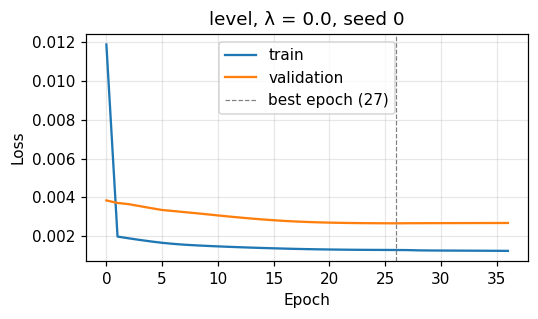

λ=0.0  seed=0  epochs= 27  skill=  5.7 %  F1@80=0.003
Epoch 1/100
262/262 - 20s - 75ms/step - loss: 0.0130 - val_loss: 0.0039
Epoch 2/100
262/262 - 19s - 72ms/step - loss: 0.0020 - val_loss: 0.0039
Epoch 3/100
262/262 - 19s - 74ms/step - loss: 0.0019 - val_loss: 0.0039
Epoch 4/100
262/262 - 18s - 69ms/step - loss: 0.0018 - val_loss: 0.0039
Epoch 5/100
262/262 - 22s - 86ms/step - loss: 0.0017 - val_loss: 0.0037
Epoch 6/100
262/262 - 18s - 70ms/step - loss: 0.0017 - val_loss: 0.0035
Epoch 7/100
262/262 - 19s - 72ms/step - loss: 0.0016 - val_loss: 0.0033
Epoch 8/100
262/262 - 20s - 75ms/step - loss: 0.0016 - val_loss: 0.0031
Epoch 9/100
262/262 - 18s - 70ms/step - loss: 0.0015 - val_loss: 0.0030
Epoch 10/100
262/262 - 20s - 75ms/step - loss: 0.0015 - val_loss: 0.0030
Epoch 11/100
262/262 - 18s - 70ms/step - loss: 0.0015 - val_loss: 0.0029
Epoch 12/100
262/262 - 20s - 76ms/step - loss: 0.0014 - val_loss: 0.0029
Epoch 13/100
262/262 - 20s - 76ms/step - loss: 0.0014 - val_loss: 0.0028
Epoch 

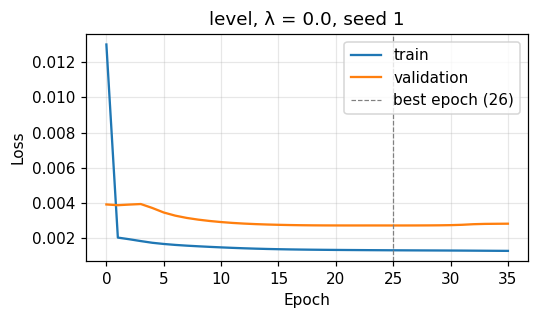

λ=0.0  seed=1  epochs= 26  skill=  4.9 %  F1@80=0.008
Epoch 1/100
262/262 - 20s - 75ms/step - loss: 0.0108 - val_loss: 0.0038
Epoch 2/100
262/262 - 20s - 76ms/step - loss: 0.0020 - val_loss: 0.0037
Epoch 3/100
262/262 - 18s - 70ms/step - loss: 0.0019 - val_loss: 0.0036
Epoch 4/100
262/262 - 20s - 75ms/step - loss: 0.0018 - val_loss: 0.0035
Epoch 5/100
262/262 - 19s - 72ms/step - loss: 0.0018 - val_loss: 0.0034
Epoch 6/100
262/262 - 18s - 70ms/step - loss: 0.0017 - val_loss: 0.0033
Epoch 7/100
262/262 - 20s - 76ms/step - loss: 0.0016 - val_loss: 0.0032
Epoch 8/100
262/262 - 18s - 69ms/step - loss: 0.0016 - val_loss: 0.0032
Epoch 9/100
262/262 - 18s - 69ms/step - loss: 0.0015 - val_loss: 0.0031
Epoch 10/100
262/262 - 20s - 76ms/step - loss: 0.0015 - val_loss: 0.0030
Epoch 11/100
262/262 - 18s - 69ms/step - loss: 0.0015 - val_loss: 0.0030
Epoch 12/100
262/262 - 18s - 69ms/step - loss: 0.0014 - val_loss: 0.0029
Epoch 13/100
262/262 - 20s - 77ms/step - loss: 0.0014 - val_loss: 0.0029
Epoch 

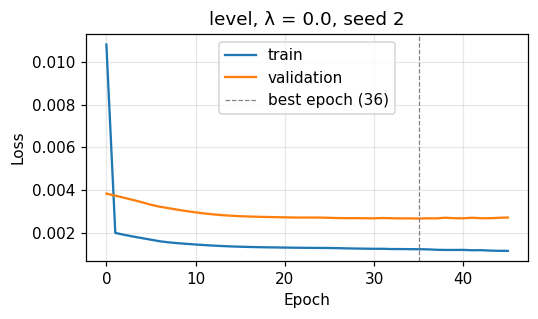

λ=0.0  seed=2  epochs= 36  skill=  1.3 %  F1@80=0.010
Epoch 1/100
262/262 - 22s - 83ms/step - loss: 0.0142 - val_loss: 0.0047
Epoch 2/100
262/262 - 18s - 69ms/step - loss: 0.0025 - val_loss: 0.0046
Epoch 3/100
262/262 - 18s - 70ms/step - loss: 0.0023 - val_loss: 0.0045
Epoch 4/100
262/262 - 21s - 79ms/step - loss: 0.0022 - val_loss: 0.0044
Epoch 5/100
262/262 - 20s - 76ms/step - loss: 0.0022 - val_loss: 0.0043
Epoch 6/100
262/262 - 20s - 77ms/step - loss: 0.0021 - val_loss: 0.0042
Epoch 7/100
262/262 - 18s - 70ms/step - loss: 0.0020 - val_loss: 0.0041
Epoch 8/100
262/262 - 20s - 75ms/step - loss: 0.0020 - val_loss: 0.0040
Epoch 9/100
262/262 - 18s - 70ms/step - loss: 0.0019 - val_loss: 0.0039
Epoch 10/100
262/262 - 18s - 68ms/step - loss: 0.0019 - val_loss: 0.0038
Epoch 11/100
262/262 - 20s - 76ms/step - loss: 0.0019 - val_loss: 0.0038
Epoch 12/100
262/262 - 19s - 71ms/step - loss: 0.0018 - val_loss: 0.0037
Epoch 13/100
262/262 - 18s - 69ms/step - loss: 0.0018 - val_loss: 0.0037
Epoch 

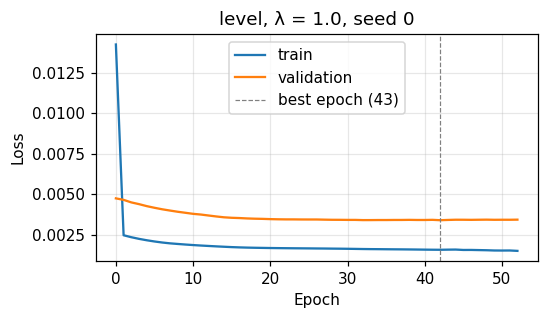

λ=1.0  seed=0  epochs= 43  skill=  1.2 %  F1@80=0.154
Epoch 1/100
262/262 - 21s - 82ms/step - loss: 0.0150 - val_loss: 0.0049
Epoch 2/100
262/262 - 18s - 69ms/step - loss: 0.0025 - val_loss: 0.0048
Epoch 3/100
262/262 - 18s - 69ms/step - loss: 0.0024 - val_loss: 0.0048
Epoch 4/100
262/262 - 21s - 82ms/step - loss: 0.0023 - val_loss: 0.0048
Epoch 5/100
262/262 - 18s - 70ms/step - loss: 0.0022 - val_loss: 0.0046
Epoch 6/100
262/262 - 19s - 74ms/step - loss: 0.0021 - val_loss: 0.0044
Epoch 7/100
262/262 - 18s - 70ms/step - loss: 0.0020 - val_loss: 0.0042
Epoch 8/100
262/262 - 20s - 77ms/step - loss: 0.0020 - val_loss: 0.0040
Epoch 9/100
262/262 - 20s - 76ms/step - loss: 0.0019 - val_loss: 0.0039
Epoch 10/100
262/262 - 18s - 70ms/step - loss: 0.0019 - val_loss: 0.0038
Epoch 11/100
262/262 - 18s - 70ms/step - loss: 0.0019 - val_loss: 0.0038
Epoch 12/100
262/262 - 20s - 76ms/step - loss: 0.0018 - val_loss: 0.0037
Epoch 13/100
262/262 - 18s - 70ms/step - loss: 0.0018 - val_loss: 0.0037
Epoch 

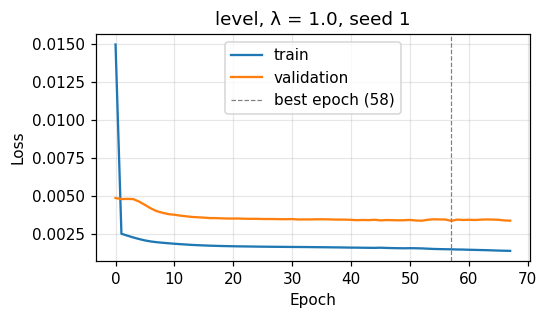

λ=1.0  seed=1  epochs= 58  skill= -4.5 %  F1@80=0.191
Epoch 1/100
262/262 - 21s - 80ms/step - loss: 0.0127 - val_loss: 0.0048
Epoch 2/100
262/262 - 20s - 76ms/step - loss: 0.0025 - val_loss: 0.0047
Epoch 3/100
262/262 - 18s - 70ms/step - loss: 0.0024 - val_loss: 0.0045
Epoch 4/100
262/262 - 20s - 76ms/step - loss: 0.0023 - val_loss: 0.0044
Epoch 5/100
262/262 - 18s - 69ms/step - loss: 0.0022 - val_loss: 0.0043
Epoch 6/100
262/262 - 18s - 69ms/step - loss: 0.0021 - val_loss: 0.0041
Epoch 7/100
262/262 - 20s - 76ms/step - loss: 0.0020 - val_loss: 0.0040
Epoch 8/100
262/262 - 19s - 72ms/step - loss: 0.0020 - val_loss: 0.0039
Epoch 9/100
262/262 - 19s - 71ms/step - loss: 0.0019 - val_loss: 0.0038
Epoch 10/100
262/262 - 20s - 76ms/step - loss: 0.0019 - val_loss: 0.0037
Epoch 11/100
262/262 - 19s - 72ms/step - loss: 0.0018 - val_loss: 0.0037
Epoch 12/100
262/262 - 20s - 77ms/step - loss: 0.0018 - val_loss: 0.0036
Epoch 13/100
262/262 - 18s - 69ms/step - loss: 0.0018 - val_loss: 0.0036
Epoch 

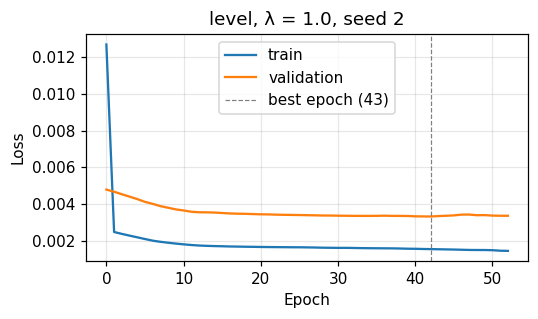

λ=1.0  seed=2  epochs= 43  skill= -0.3 %  F1@80=0.140
Epoch 1/100
262/262 - 21s - 81ms/step - loss: 0.0121 - val_loss: 0.0039
Epoch 2/100
262/262 - 19s - 74ms/step - loss: 0.0020 - val_loss: 0.0038
Epoch 3/100
262/262 - 20s - 76ms/step - loss: 0.0019 - val_loss: 0.0037
Epoch 4/100
262/262 - 18s - 69ms/step - loss: 0.0019 - val_loss: 0.0036
Epoch 5/100
262/262 - 18s - 69ms/step - loss: 0.0018 - val_loss: 0.0035
Epoch 6/100
262/262 - 20s - 76ms/step - loss: 0.0017 - val_loss: 0.0034
Epoch 7/100
262/262 - 18s - 69ms/step - loss: 0.0016 - val_loss: 0.0034
Epoch 8/100
262/262 - 23s - 86ms/step - loss: 0.0016 - val_loss: 0.0033
Epoch 9/100
262/262 - 18s - 69ms/step - loss: 0.0016 - val_loss: 0.0033
Epoch 10/100
262/262 - 18s - 70ms/step - loss: 0.0015 - val_loss: 0.0032
Epoch 11/100
262/262 - 20s - 76ms/step - loss: 0.0015 - val_loss: 0.0031
Epoch 12/100
262/262 - 18s - 71ms/step - loss: 0.0015 - val_loss: 0.0031
Epoch 13/100
262/262 - 19s - 72ms/step - loss: 0.0015 - val_loss: 0.0030
Epoch 

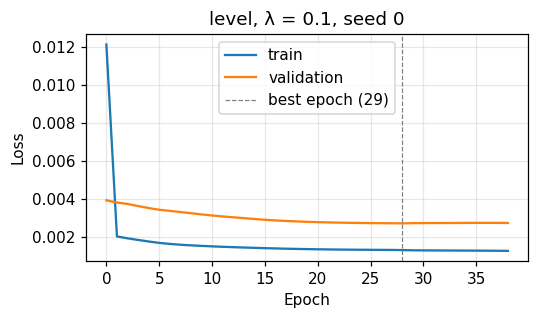

λ=0.1  seed=0  epochs= 29  skill=  5.2 %  F1@80=0.000
Epoch 1/100
262/262 - 22s - 82ms/step - loss: 0.0127 - val_loss: 0.0041
Epoch 2/100
262/262 - 18s - 69ms/step - loss: 0.0021 - val_loss: 0.0040
Epoch 3/100
262/262 - 19s - 73ms/step - loss: 0.0020 - val_loss: 0.0039
Epoch 4/100
262/262 - 19s - 72ms/step - loss: 0.0019 - val_loss: 0.0038
Epoch 5/100
262/262 - 18s - 70ms/step - loss: 0.0018 - val_loss: 0.0037
Epoch 6/100
262/262 - 20s - 76ms/step - loss: 0.0018 - val_loss: 0.0036
Epoch 7/100
262/262 - 18s - 69ms/step - loss: 0.0017 - val_loss: 0.0035
Epoch 8/100
262/262 - 18s - 69ms/step - loss: 0.0017 - val_loss: 0.0035
Epoch 9/100
262/262 - 20s - 75ms/step - loss: 0.0016 - val_loss: 0.0034
Epoch 10/100
262/262 - 18s - 69ms/step - loss: 0.0016 - val_loss: 0.0033
Epoch 11/100
262/262 - 18s - 68ms/step - loss: 0.0016 - val_loss: 0.0033
Epoch 12/100
262/262 - 20s - 76ms/step - loss: 0.0016 - val_loss: 0.0032
Epoch 13/100
262/262 - 18s - 69ms/step - loss: 0.0015 - val_loss: 0.0032
Epoch 

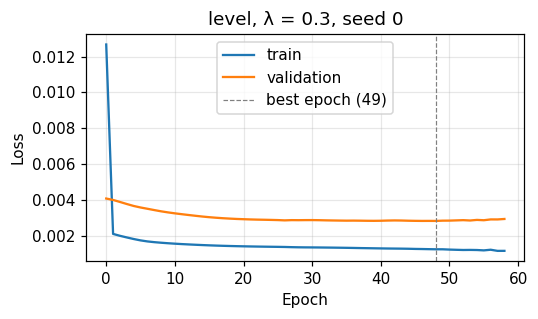

λ=0.3  seed=0  epochs= 49  skill= -2.4 %  F1@80=0.064
Epoch 1/100
262/262 - 22s - 83ms/step - loss: 0.0190 - val_loss: 0.0066
Epoch 2/100
262/262 - 19s - 71ms/step - loss: 0.0034 - val_loss: 0.0063
Epoch 3/100
262/262 - 19s - 74ms/step - loss: 0.0032 - val_loss: 0.0061
Epoch 4/100
262/262 - 19s - 72ms/step - loss: 0.0031 - val_loss: 0.0059
Epoch 5/100
262/262 - 18s - 69ms/step - loss: 0.0029 - val_loss: 0.0058
Epoch 6/100
262/262 - 20s - 76ms/step - loss: 0.0029 - val_loss: 0.0057
Epoch 7/100
262/262 - 18s - 70ms/step - loss: 0.0028 - val_loss: 0.0056
Epoch 8/100
262/262 - 18s - 69ms/step - loss: 0.0027 - val_loss: 0.0054
Epoch 9/100
262/262 - 20s - 76ms/step - loss: 0.0027 - val_loss: 0.0054
Epoch 10/100
262/262 - 18s - 69ms/step - loss: 0.0026 - val_loss: 0.0053
Epoch 11/100
262/262 - 18s - 69ms/step - loss: 0.0026 - val_loss: 0.0052
Epoch 12/100
262/262 - 20s - 76ms/step - loss: 0.0026 - val_loss: 0.0052
Epoch 13/100
262/262 - 18s - 69ms/step - loss: 0.0026 - val_loss: 0.0051
Epoch 

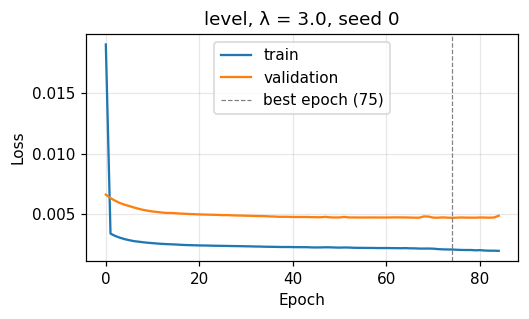

λ=3.0  seed=0  epochs= 75  skill= -7.4 %  F1@80=0.213


In [9]:
log = pd.read_csv(RESULTS_FILE) if os.path.exists(RESULTS_FILE) else pd.DataFrame()

def pred_file(lam, seed):
    return f"pred_{TARGET}_lam{lam}_seed{seed}.npy"

for lam, seed in RUNS:
    if os.path.exists(pred_file(lam, seed)):
        print(f"λ={lam:<4} seed={seed}: forecasts found, not trained again")
        continue
    res = run_experiment(TARGET, lam, INPUTS, seed)
    log = pd.concat([log, pd.DataFrame([res])], ignore_index=True)
    log.to_csv(RESULTS_FILE, index=False)                          # save after every run
    print(f"λ={lam:<4} seed={seed}  epochs={res['best epoch']:3d}  "
          f"skill={res['skill all']:5.1f} %  F1@{THRESHOLD}={res[f'F1 @{THRESHOLD}']:.3f}")

## 9. Results
All tables are computed from the saved test forecasts. With several seeds, values are shown as **mean ± standard deviation**; λ values with one seed show a single value.

In [10]:
# =====================================================================
# A) Collect forecasts and define the metrics
# =====================================================================
from sklearn.metrics import mean_absolute_error, mean_squared_error

(_, Y_tr, now_tr, _), _, (_, Y_te, now_te, t_te) = get_windows(INPUTS).values()
types_te = np.array([DAY_TYPE[d] for d in t_te.date])
broken, clear = types_te == "broken clouds", types_te == "clear"
obs_steps = np.diff(np.hstack([now_te, Y_te]), axis=1)[broken]     # real 10-s steps (broken-cloud day)

runs = [("persistence", "-", np.repeat(now_te, HORIZON, axis=1))]
for lam, seed in sorted(RUNS):                                      # sorted by λ, then seed
    if os.path.exists(pred_file(lam, seed)):
        runs.append((f"λ = {lam:g}", seed, np.load(pred_file(lam, seed))))
MODELS = list(dict.fromkeys(name for name, _, _ in runs))

def ramp_counts(obs, pred, thr):
    # counts for drops and rises together (ramp = 10-s step larger than thr along the forecast path)
    res = {"predicted ramps": 0, "real ramps caught": 0, "correct": 0, "real": 0}
    for label, sign in [("drops", -1), ("rises", +1)]:
        o, p = sign * obs > thr, sign * pred > thr
        caught = (o & widen(p, TOL)).sum()
        res["real"] += o.sum(); res["predicted ramps"] += p.sum()
        res["real ramps caught"] += caught; res["correct"] += (p & widen(o, TOL)).sum()
        res[f"recall {label}"] = caught / o.sum() if o.sum() else np.nan
    res["false alarms"] = res["predicted ramps"] - res["correct"]
    res["precision"] = res["correct"] / res["predicted ramps"] if res["predicted ramps"] else np.nan
    res["recall"] = res["real ramps caught"] / res["real"]
    p_, r_ = res["precision"], res["recall"]
    res["F1"] = 2 * p_ * r_ / (p_ + r_) if res["predicted ramps"] and (p_ + r_) else 0.0
    del res["correct"], res["real"]
    return res

rows = []
for name, seed, P in runs:
    pred_steps = np.diff(np.hstack([now_te, P]), axis=1)[broken]
    rows.append({
        "model": name, "seed": seed,
        "MAE broken":  mean_absolute_error(Y_te[broken].ravel(), P[broken].ravel()),
        "RMSE broken": np.sqrt(mean_squared_error(Y_te[broken].ravel(), P[broken].ravel())),
        "MAE clear":   mean_absolute_error(Y_te[clear].ravel(), P[clear].ravel()),
        "RMSE clear":  np.sqrt(mean_squared_error(Y_te[clear].ravel(), P[clear].ravel())),
        **ramp_counts(obs_steps, pred_steps, THRESHOLD)})
res = pd.DataFrame(rows)

def mean_std(df, by, cols, digits):
    # "mean ± std" over the seeds; only the mean when there is a single value
    g = df.groupby(by, sort=False)[cols]
    rnd = (lambda x: x.round(digits)) if digits else (lambda x: x.round().astype("Int64"))
    mean, std = rnd(g.mean()), rnd(g.std())
    return mean.astype(str) + (" ± " + std.astype(str)).where(g.std().notna(), "")

print(f"Real ramp steps on the broken-cloud test day: {(np.abs(obs_steps) > THRESHOLD).sum()}")

Real ramp steps on the broken-cloud test day: 1500


### A. Accuracy and ramps for each λ
- **Accuracy:** MAE and RMSE on the broken-cloud day and on the clear day (W/m²).
- **Ramps** (broken-cloud day, threshold 80 W/m², along all forecast paths): predicted ramps, real ramps caught, false alarms, precision, recall (also for drops and rises separately) and F1.

In [11]:
ACC_COLS  = ["MAE broken", "RMSE broken", "MAE clear", "RMSE clear"]
CNT_COLS  = ["predicted ramps", "real ramps caught", "false alarms"]
RATE_COLS = ["precision", "recall", "recall drops", "recall rises", "F1"]

print("Accuracy (W/m²)")
display(mean_std(res, "model", ACC_COLS, 1).reindex(MODELS))
print(f"\nRamps on the broken-cloud day (threshold {THRESHOLD} W/m²)")
display(pd.concat([mean_std(res, "model", CNT_COLS, 0),
                   mean_std(res, "model", RATE_COLS, 3)], axis=1).reindex(MODELS))

Accuracy (W/m²)


,MAE broken,RMSE broken,MAE clear,RMSE clear
model,,,,
persistence,30.5,89.8,1.7,2.2
λ = 0,35.7 ± 1.1,86.0 ± 2.2,5.4 ± 2.1,6.9 ± 2.6
λ = 0.1,34.8,85.0,4.0,5.2
λ = 0.3,38.2,91.8,3.4,4.2
λ = 1,38.4 ± 1.8,90.8 ± 2.6,3.5 ± 0.2,4.6 ± 0.1
λ = 3,40.1,96.3,3.9,5.4



Ramps on the broken-cloud day (threshold 80 W/m²)


,predicted ramps,real ramps caught,false alarms,precision,recall,recall drops,recall rises,F1
model,,,,,,,,
persistence,0,0,0,nan,0.0,0.0,0.0,0.0
λ = 0,26 ± 30,5 ± 3,22 ± 27,0.284 ± 0.196,0.004 ± 0.002,0.0 ± 0.001,0.007 ± 0.004,0.007 ± 0.004
λ = 0.1,0,0,0,nan,0.0,0.0,0.0,0.0
λ = 0.3,272,58,222,0.184,0.039,0.017,0.062,0.064
λ = 1,627 ± 152,178 ± 44,463 ± 125,0.264 ± 0.04,0.119 ± 0.029,0.077 ± 0.028,0.163 ± 0.035,0.162 ± 0.027
λ = 3,1127,277,843,0.252,0.185,0.11,0.265,0.213


**Results: effect of λ (λ = 0 and 1: 3 seeds; λ = 0.1, 0.3 and 3: one seed)**

- **There is a sharp trade-off between accuracy and ramp detection.** From λ = 0.3 on, a larger λ catches more ramps (58 → 178 → 277 of 1500 ramp steps for λ = 0.3, 1, 3) and increases the RMSE on the broken-cloud day (91.8 → 90.8 → 96.3 W/m², against 89.8 W/m² for persistence).
- **A small λ improves accuracy but catches no ramps.** λ = 0.1 gives the lowest RMSE on the broken-cloud day of all models (85.0 W/m²) and a lower clear-day error than plain MSE (MAE 4.0 vs 5.4 W/m²), but predicts no ramps. We suppose that a small ramp term mainly penalises unnecessary changes, acting as a regulariser.
- **Ramp detection switches on between λ = 0.1 and 0.3**, and with it the RMSE rises by about 6–7 W/m², more than the variation between seeds (± 2.2 W/m²). No λ keeps the accuracy of plain MSE while catching a useful share of the ramps.
- **λ = 0.3 is not a good compromise:** about as accurate as λ = 1, but it catches only a third of the ramps.
- **At every λ, rises are caught about twice as often as drops:** a larger λ does not make the models foresee clouds, it makes them predict larger changes.

**Choice.** λ = 1 is kept as the ramp-aware setting: its RMSE is about equal to persistence and it catches 12 % of the ramp steps (3 seeds). λ = 3 marks the high end of the trade-off (most ramps, accuracy clearly below persistence). λ = 0.1 is confirmed with two more seeds, since it may be a more accurate baseline than plain MSE.

### B. Trade-off: accuracy vs ramp detection
Each point is one λ (mean over the seeds; bars = ± standard deviation where 3 seeds exist). **Left** is more accurate (lower RMSE on the broken-cloud day), **up** catches more ramps. The dashed line marks the RMSE of persistence. The best balance lies towards the upper left.

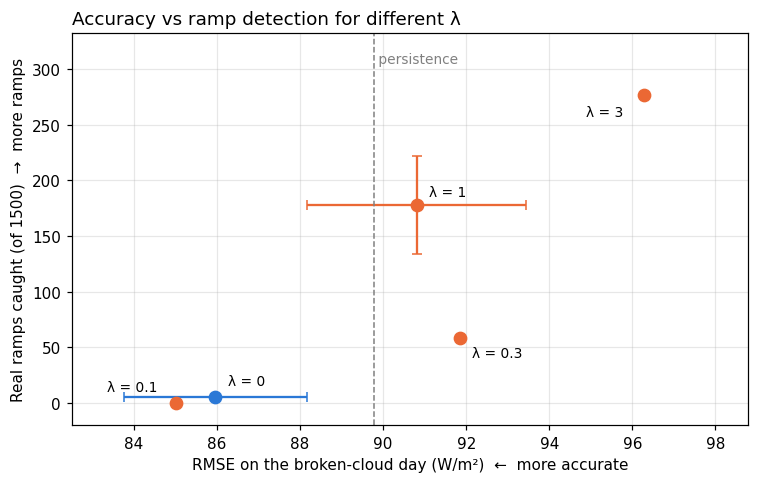

In [15]:
fig, ax = plt.subplots(figsize=(7, 4.5))
lstm = res[res["model"] != "persistence"]

# Label position for each point (offset in points), so close points do not overlap
OFFSET = {"λ = 0": (8, 8), "λ = 0.1": (-45, 8), "λ = 0.3": (8, -12), "λ = 1": (8, 6), "λ = 3": (-38, -14)}

for name, r in lstm.groupby("model", sort=False):
    x, y = r["RMSE broken"], r["real ramps caught"]
    ax.errorbar(x.mean(), y.mean(),
                xerr=x.std() if len(r) > 1 else None, yerr=y.std() if len(r) > 1 else None,
                fmt="o", ms=8, capsize=3, color="#eb6834" if name != "λ = 0" else "#2a78d6")
    ax.annotate(name, (x.mean(), y.mean()), xytext=OFFSET.get(name, (8, 5)),
                textcoords="offset points", fontsize=9)

pers_rmse = res.loc[res["model"] == "persistence", "RMSE broken"].iloc[0]
ax.axvline(pers_rmse, color="gray", ls="--", lw=1)

# Some space around the points, so no label is cut off
x_all, y_all = lstm.groupby("model")["RMSE broken"].mean(), lstm.groupby("model")["real ramps caught"].mean()
ax.set_xlim(x_all.min() - 2.5, x_all.max() + 2.5)
ax.set_ylim(-20, y_all.max() * 1.2)
ax.text(pers_rmse, ax.get_ylim()[1] * 0.95, " persistence", color="gray", fontsize=9, va="top")

ax.set_xlabel("RMSE on the broken-cloud day (W/m²)  ←  more accurate")
ax.set_ylabel(f"Real ramps caught (of {(np.abs(obs_steps) > THRESHOLD).sum()})  →  more ramps")
ax.set_title("Accuracy vs ramp detection for different λ", loc="left")
plt.tight_layout(); plt.show()

**Trade-off.** The points form a clear trade-off: λ = 0 and λ = 0.1 are the most accurate (RMSE below persistence) but catch almost no ramps; λ = 1 catches about 180 ramp steps with an RMSE about equal to persistence (its error bar crosses the persistence line); λ = 3 catches the most ramps but is clearly less accurate than persistence. λ = 0.3 lies below and to the right of λ = 1 (fewer ramps at about the same accuracy) and is therefore not a useful choice. The accuracy advantage of λ = 0.1 over λ = 0 lies within the variation between seeds of λ = 0 and is confirmed with two more seeds.

### C. What the forecasts look like
Measured irradiance and the forecasts 30 s ahead for several λ (seed 0), for 20 minutes on the broken-cloud test day. A larger λ should give sharper drops and rises, but also more ups and downs during calm periods.

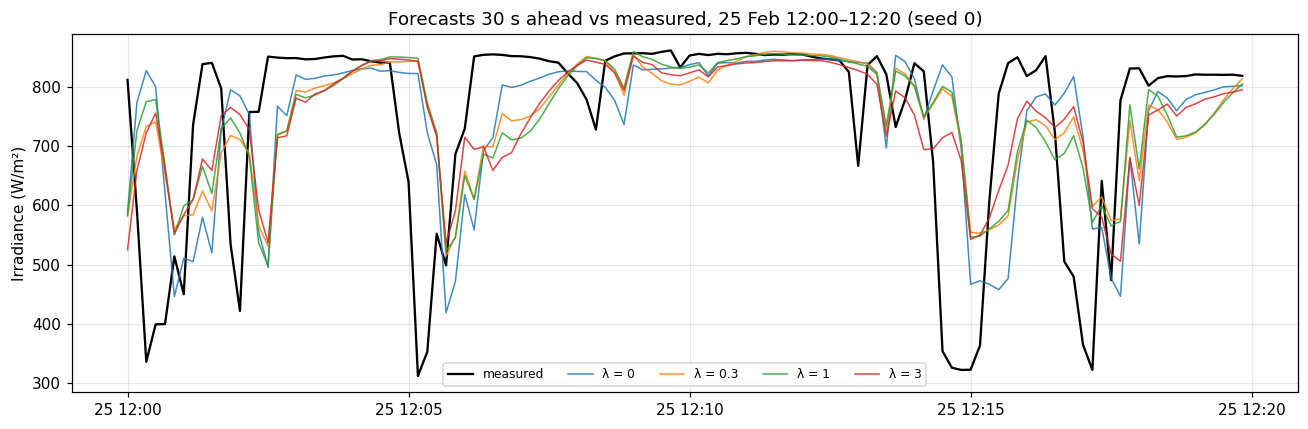

In [13]:
LEAD_SHOW, SHOW_LAMBDAS = 30, [0.0, 0.3, 1.0, 3.0]
k = list(LEADS).index(LEAD_SHOW)
t_target = t_te + pd.Timedelta(seconds=LEAD_SHOW)
show = (t_target >= "2013-02-25 12:00") & (t_target < "2013-02-25 12:20")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(t_target[show], Y_te[show, k], color="k", lw=1.5, label="measured")
for lam in SHOW_LAMBDAS:
    if os.path.exists(pred_file(lam, 0)):
        ax.plot(t_target[show], np.load(pred_file(lam, 0))[show, k], lw=1, alpha=0.85, label=f"λ = {lam:g}")
ax.set_ylabel("Irradiance (W/m²)")
ax.set_title(f"Forecasts {LEAD_SHOW} s ahead vs measured, 25 Feb 12:00–12:20 (seed 0)")
ax.legend(fontsize=8, ncol=5); plt.tight_layout(); plt.show()

**Forecasts for different λ (30 s ahead, seed 0).** A larger λ does not make the models foresee clouds: at the large drops (around 12:05 and 12:15) all forecasts fall only after the measured irradiance, and at these drops λ = 0 even falls deeper (to about 420–460 W/m²) than λ = 1 and λ = 3 (about 520–550 W/m²). During recoveries, the larger λ values predict longer dips (e.g. about 700 W/m² around 12:07, when the measured irradiance is already back at about 850 W/m²), which raises their RMSE.

This view shows one lead time (+30 s) taken from many successive forecasts, while the ramp metric looks at the 10-s steps *within* each forecast path. The ramp-aware loss rewards large steps within a path: the forecast paths become sharper, which increases the number of ramps caught, but the steps are often in the wrong place, which increases the RMSE.

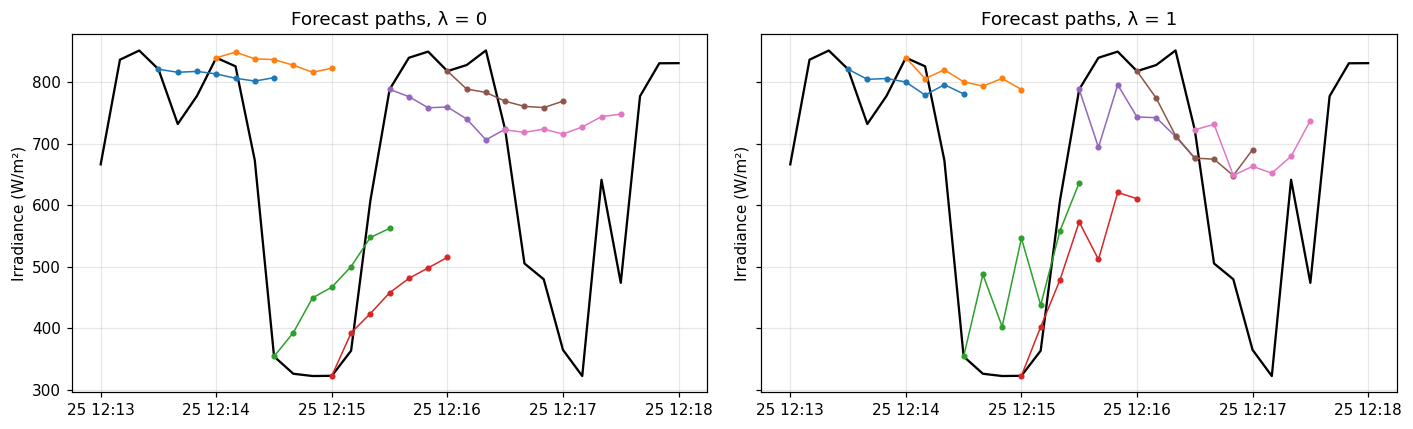

In [16]:
# Whole forecast paths (now → +60 s) around the drop at 12:15, for λ = 0 and λ = 1 (seed 0)
origins = (t_te >= "2013-02-25 12:13:30") & (t_te <= "2013-02-25 12:16:30")
idx = np.where(origins)[0][::3]                               # one forecast every 30 s

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
meas = data.loc["2013-02-25 12:13:00":"2013-02-25 12:18:00", "G"]
for ax, lam in zip(axes, [0.0, 1.0]):
    P = np.load(pred_file(lam, 0))
    ax.plot(meas.index, meas, color="k", lw=1.5, label="measured")
    for i in idx:
        times = t_te[i] + pd.to_timedelta(np.arange(0, HORIZON + 1) * STEP_S, unit="s")
        ax.plot(times, np.r_[now_te[i, 0], P[i]], "-o", ms=3, lw=1)   # one forecast path, starting at "now"
    ax.set_title(f"Forecast paths, λ = {lam:g}"); ax.set_ylabel("Irradiance (W/m²)")
plt.tight_layout(); plt.show()

**Forecast paths around the drop at 12:15 (seed 0).** Each coloured line is one forecast, from the current value ("now") to +60 s.

- **λ = 0 (MSE): smooth paths that hedge.** Before the drop the paths are flat (the drop is not foreseen). During the shade, the paths rise slowly and evenly (e.g. 355 → 560 W/m² within one minute), between "stays dark" and "sun returns", while the measured irradiance stays low and then jumps back to about 800 W/m² within 10–20 s. This is the smoothing effect of MSE.
- **λ = 1 (ramp-aware): large steps, but zigzagging.** The paths contain steps of about ±100–150 W/m², often alternating up and down (e.g. 355 → 490 → 400 → 545 → 435 W/m²). The ramp term only compares the *size* of each 10-s step with the real one, not its direction or timing, and the model satisfies it by oscillating around the smooth MSE path rather than by predicting one well-timed jump.

This explains the E1 and E2 results: the oscillations produce more predicted ramps, some of which fall, partly by chance, within ±10 s of a real ramp (higher recall), but most of which are false alarms (precision about 0.26), and they increase the RMSE. The gain in recall should therefore not be read as real foresight of clouds.

**Idea for an improved ramp term:** compare the *sorted* step sizes of the predicted and real paths (largest with largest, and so on). This keeps the term independent of the exact timing (no double penalty) but penalises additional large steps, i.e. zigzags. It is similar in spirit to the position-independent amplitude term of Subich et al. (2025).

## Overall conclusion of E2

### What we did
We trained the univariate LSTM (value target) with five weights of the ramp term, **λ = 0, 0.1, 0.3, 1 and 3**. λ = 0 and λ = 1 come from E1 (3 seeds each); the other values were trained with one seed. For each λ we measured accuracy (MAE and RMSE on the broken-cloud and the clear test day) and ramp detection on the broken-cloud day (threshold 80 W/m² per 10 s, 1500 ramp steps). We also looked at the forecasts at +30 s and at whole forecast paths (now → +60 s) around one large drop.

### Why
In E1, the ramp-aware loss with λ = 1 made the LSTM catch about 35 times more ramps than plain MSE, but it cost accuracy. λ = 1 had not been tuned, so the question was whether a different λ gives a better balance: most of the accuracy of plain MSE together with a useful share of the ramps.

### What we found
| λ | RMSE broken-cloud day (W/m²) | Real ramps caught (of 1500) | MAE clear day (W/m²) |
|---|---|---|---|
| persistence | 89.8 | 0 | 1.7 |
| 0 (MSE) | 86.0 ± 2.2 | 5 ± 3 | 5.4 ± 2.1 |
| 0.1 | 85.0 | 0 | 4.0 |
| 0.3 | 91.8 | 58 | 3.4 |
| 1 | 90.8 ± 2.6 | 178 ± 44 | 3.5 ± 0.2 |
| 3 | 96.3 | 277 | 3.9 |

1. **There is a sharp trade-off.** From λ = 0.3 on, a larger λ catches more ramps (58 → 178 → 277) and makes the forecasts less accurate (RMSE 91.8 → 90.8 → 96.3 W/m², against 89.8 W/m² for persistence). No λ keeps the accuracy of plain MSE while catching a useful share of the ramps.
2. **Ramp detection switches on between λ = 0.1 and 0.3**, and with it the RMSE rises by about 6–7 W/m², more than the variation between seeds.
3. **A small λ (0.1) catches no ramps, but was the most accurate model** (RMSE 85.0 W/m²) and improved the clear day compared with plain MSE. We suppose that a small ramp term mainly penalises unnecessary changes, acting as a regulariser. This is a single-seed result and still needs to be confirmed.
4. **λ = 1 remains the most sensible ramp-aware setting:** its RMSE is about equal to persistence, and it catches about 12 % of the ramp steps (3 seeds). λ = 0.3 is not a useful choice (about the same accuracy as λ = 1, but a third of the ramps), and λ = 3 marks the high end of the trade-off.
5. **A larger λ does not make the model foresee clouds.** At every λ, rises (the sun returning) were caught about twice as often as drops (a cloud arriving), and at +30 s all forecasts fall only after the measured irradiance.
6. **How the ramp term really works.** The forecast paths show that with λ = 0 the paths are smooth and hedge between "stays dark" and "sun returns", while with λ = 1 they contain large steps that often alternate up and down (e.g. 355 → 490 → 400 → 545 → 435 W/m²). The ramp term only compares the *size* of each 10-s step with the real one, not its direction or timing, and the model satisfies it by oscillating around the smooth MSE path. Some of these steps fall, partly by chance, within ±10 s of a real ramp (higher recall); most are false alarms (precision about 0.26), and they raise the RMSE. **The gain in recall should therefore not be read as real foresight of clouds.**

### How this relates to the literature
Recent studies agree that accuracy and ramp detection must both be reported, because RMSE-trained models can have good skill while missing most ramps (Nouri et al., 2024; SolarBench, 2026). Methods that improve ramp detection mostly rely on sky images or generative models, which produce realistic fluctuations instead of smooth averages; Nouri et al. conclude that the best model "depends on use case". We did not find a study that maps the trade-off as a function of the loss weight, or that shows how a ramp term can increase recall through oscillating forecasts.

### Limitations
- λ = 0.1, 0.3 and 3 were trained with one seed; differences smaller than the seed variation of λ = 0 and λ = 1 (about ± 2–3 W/m² RMSE, ± 44 ramps caught) are not reliable.
- The LSTM is a simple, untuned baseline with irradiance as the only input, tested on one broken-cloud day.

### Next
- **Confirm λ = 0.1** with two more seeds (section 10).
- **Improved ramp term (idea):** compare the *sorted* step sizes of predicted and real paths, which keeps the term independent of the exact timing but penalises additional large steps (zigzags).
- **New direction suggested by the results:** since the timing of a ramp can hardly be learned from past irradiance, but its *chance* can (3 % after a calm period vs 55 % after a restless one, in the data exploration), we next test whether the LSTM can forecast the **probability of a ramp in the next 60 s**, compared with a simple rule based on recent ramps (ROC-AUC).